# Day 3: Hyperparameter Tuning and Model Optimization

## Objective
Optimize Decision Tree, Random Forest and SVM using GridSearchCV
and Stratified K-Fold Cross-Validation.

Random Forest was the winning model on Day 2.

We will tune all three candidates and select the strongest
generalizing model based on cross-validation performance.

In [1]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import matplotlib.pyplot as plt

In [2]:
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

CLEANED_DATA_PATH = (
    BASE_DIR / "data" / "processed" / "cleaned_data.csv"
)

print("Project directory:", BASE_DIR)
print("Dataset exists:", CLEANED_DATA_PATH.exists())

Project directory: d:\RetailMind
Dataset exists: True


In [3]:
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

print("Project directory:", BASE_DIR)

cleaned_files = [
    file for file in BASE_DIR.rglob("*.csv")
    if file.name.lower() == "cleaned_data.csv"
]

for file in cleaned_files:
    print("Cleaned dataset found:", file)

Project directory: d:\RetailMind
Cleaned dataset found: d:\RetailMind\data\processed\cleaned_data.csv


In [4]:
import sys

sys.path.insert(0, str(BASE_DIR / "src"))

In [5]:
if not cleaned_files:
    raise FileNotFoundError(
        "cleaned_data.csv was not found inside RetailMind."
    )

CLEANED_DATA_PATH = cleaned_files[0]

df = pd.read_csv(CLEANED_DATA_PATH)

print("Dataset loaded successfully!")
print("Location:", CLEANED_DATA_PATH)
print("Shape:", df.shape)

Dataset loaded successfully!
Location: d:\RetailMind\data\processed\cleaned_data.csv
Shape: (7043, 21)


In [6]:
X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 19)
Target: (7043,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5634, 19)
Testing: (1409, 19)


In [8]:
day1_test_data = pd.read_csv(
    BASE_DIR / "data" / "processed" / "test_data.csv"
)

print(
    "Same test labels:",
    np.array_equal(
        day1_test_data["Churn"].to_numpy(),
        y_test.to_numpy()
    )
)

Same test labels: True


## Cross-Validation Configuration

We use 5-fold Stratified Cross-Validation to preserve
the churn class distribution across all folds.

In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [10]:
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    print(f"\nFold {fold}")

    print(
        "Training churn proportion:",
        round(y_fold_train.mean(), 3)
    )

    print(
        "Validation churn proportion:",
        round(y_fold_val.mean(), 3)
    )


Fold 1
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 2
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 3
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 4
Training churn proportion: 0.265
Validation churn proportion: 0.265

Fold 5
Training churn proportion: 0.265
Validation churn proportion: 0.266


In [11]:
def tune_model(model, param_grid, X_train, y_train):

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="recall",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    grid_search.fit(X_train, y_train)

    return grid_search

In [12]:
decision_tree_grid = {
    "classifier__max_depth": [3, 5, 10, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}

In [13]:
random_forest_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 20, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__max_features": ["sqrt", 0.5]
}

In [14]:
svm_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", "auto", 0.01, 0.1],
    "classifier__kernel": ["rbf"]
}

In [15]:
total_combinations = (
    len(list(__import__("itertools").product(
        decision_tree_grid["classifier__max_depth"],
        decision_tree_grid["classifier__min_samples_split"],
        decision_tree_grid["classifier__min_samples_leaf"]
    )))
    +
    len(list(__import__("itertools").product(
        random_forest_grid["classifier__n_estimators"],
        random_forest_grid["classifier__max_depth"],
        random_forest_grid["classifier__min_samples_split"],
        random_forest_grid["classifier__min_samples_leaf"],
        random_forest_grid["classifier__max_features"]
    )))
    +
    len(list(__import__("itertools").product(
        svm_grid["classifier__C"],
        svm_grid["classifier__gamma"],
        svm_grid["classifier__kernel"]
    )))
)

print("Total parameter combinations:", total_combinations)
print("Total model fits:", total_combinations * 5)

Total parameter combinations: 148
Total model fits: 740


In [16]:
parameter_grids = {
    "Decision Tree": decision_tree_grid,
    "Random Forest": random_forest_grid,
    "SVM": svm_grid
}

for name, grid in parameter_grids.items():
    print(f"{name}: {len(grid)} hyperparameters")

Decision Tree: 3 hyperparameters
Random Forest: 5 hyperparameters
SVM: 3 hyperparameters


In [17]:
tuning_results = {}

In [18]:
import sys

sys.path.insert(0, str(BASE_DIR / "src"))

from retailmind.pipeline import build_pipeline

In [19]:
classifiers = {
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

In [20]:
models = {}

for name, classifier in classifiers.items():

    models[name] = build_pipeline(
        X_train,
        classifier=classifier
    )

    print(f"{name} pipeline created successfully!")

Decision Tree pipeline created successfully!
Random Forest pipeline created successfully!
SVM pipeline created successfully!


In [21]:
decision_tree_search = tune_model(
    model=models["Decision Tree"],
    param_grid=decision_tree_grid,
    X_train=X_train,
    y_train=y_train
)

tuning_results["Decision Tree"] = decision_tree_search

Fitting 5 folds for each of 36 candidates, totalling 180 fits


In [22]:
print("Best parameters:")
print(decision_tree_search.best_params_)

print("\nBest cross-validation recall:")
print(decision_tree_search.best_score_)

Best parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Best cross-validation recall:
0.7826086956521741


In [23]:
random_forest_search = tune_model(
    model=models["Random Forest"],
    param_grid=random_forest_grid,
    X_train=X_train,
    y_train=y_train
)

tuning_results["Random Forest"] = random_forest_search

Fitting 5 folds for each of 96 candidates, totalling 480 fits


In [24]:
print("Best parameters:")
print(random_forest_search.best_params_)

print("\nBest cross-validation recall:")
print(random_forest_search.best_score_)

Best parameters:
{'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best cross-validation recall:
0.8501672240802675


In [25]:
svm_search = tune_model(
    model=models["SVM"],
    param_grid=svm_grid,
    X_train=X_train,
    y_train=y_train
)

tuning_results["SVM"] = svm_search

Fitting 5 folds for each of 16 candidates, totalling 80 fits


d:\RetailMind\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [26]:
print("Best parameters:")
print(svm_search.best_params_)

print("\nBest cross-validation recall:")
print(svm_search.best_score_)

Best parameters:
{'classifier__C': 100, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}

Best cross-validation recall:
0.8354515050167224


In [27]:
tuning_summary = []

for name, search in tuning_results.items():

    tuning_summary.append({
        "Model": name,
        "Best CV Recall": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_summary)

tuning_df = tuning_df.sort_values(
    by="Best CV Recall",
    ascending=False
).reset_index(drop=True)

tuning_df

,Model,Best CV Recall,Best Parameters
0,Random Forest,0.850167,"{'classifier__max_depth': 5, 'classifier__max_..."
1,SVM,0.835452,"{'classifier__C': 100, 'classifier__gamma': 'a..."
2,Decision Tree,0.782609,"{'classifier__max_depth': 5, 'classifier__min_..."


In [28]:
REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

tuning_df.to_json(
    REPORT_DIR / "tuning_results.json",
    orient="records",
    indent=4
)

print("Tuning results saved successfully!")

Tuning results saved successfully!


In [29]:
tuning_df

,Model,Best CV Recall,Best Parameters
0,Random Forest,0.850167,"{'classifier__max_depth': 5, 'classifier__max_..."
1,SVM,0.835452,"{'classifier__C': 100, 'classifier__gamma': 'a..."
2,Decision Tree,0.782609,"{'classifier__max_depth': 5, 'classifier__min_..."


In [30]:
for name, search in tuning_results.items():
    print(f"\n{name}")
    print("Best CV Recall:", round(search.best_score_, 4))
    print("Best Parameters:", search.best_params_)


Decision Tree
Best CV Recall: 0.7826
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Random Forest
Best CV Recall: 0.8502
Best Parameters: {'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

SVM
Best CV Recall: 0.8355
Best Parameters: {'classifier__C': 100, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}


In [31]:
cv_results = []

for name, search in tuning_results.items():
    scores = search.cv_results_["mean_test_score"]

    cv_results.append({
        "Model": name,
        "Best CV Recall": search.best_score_,
        "Mean Training Recall": search.cv_results_["mean_train_score"][
            search.best_index_
        ],
        "Train-Validation Gap": (
            search.cv_results_["mean_train_score"][search.best_index_]
            - search.best_score_
        )
    })

cv_analysis_df = pd.DataFrame(cv_results)
cv_analysis_df

,Model,Best CV Recall,Mean Training Recall,Train-Validation Gap
0,Decision Tree,0.782609,0.813378,0.030769
1,Random Forest,0.850167,0.851505,0.001338
2,SVM,0.835452,0.835452,0.000000


In [32]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

In [33]:
best_rf_model = random_forest_search.best_estimator_

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=best_rf_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="recall",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

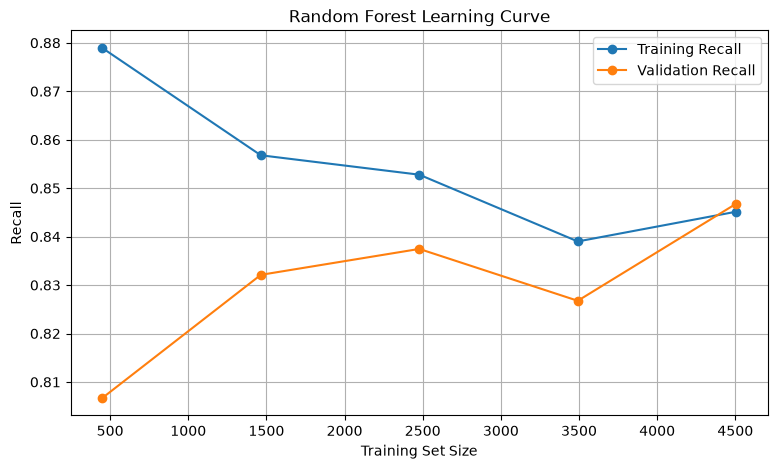

In [34]:
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(train_sizes, train_mean, marker="o", label="Training Recall")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation Recall")

plt.xlabel("Training Set Size")
plt.ylabel("Recall")
plt.title("Random Forest Learning Curve")
plt.legend()
plt.grid(True)

plt.show()

In [35]:
best_model = random_forest_search.best_estimator_

print("Selected Model: Random Forest")
print("Best Parameters:")
print(random_forest_search.best_params_)

Selected Model: Random Forest
Best Parameters:
{'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}


In [36]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

pd.DataFrame([final_metrics]).round(4)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.6856,0.4504,0.8369,0.5856,0.8106


In [38]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.91      0.63      0.75      1035
       Churn       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.68      0.73      0.67      1409
weighted avg       0.79      0.69      0.70      1409



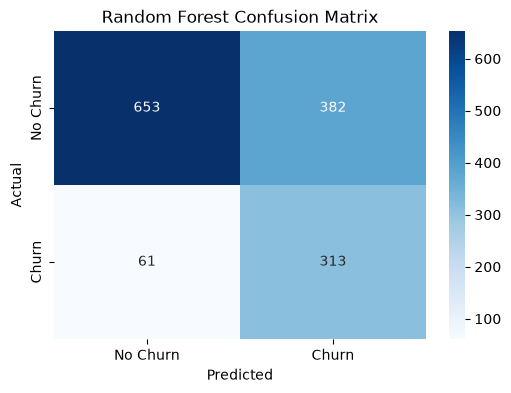

In [39]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [41]:
final_model = random_forest_search.best_estimator_

print("Final model selected:", final_model)

Final model selected: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                            

In [42]:
import joblib

MODEL_PATH = BASE_DIR / "models" / "churn_v3.joblib"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, MODEL_PATH)

print("Final model saved at:", MODEL_PATH)

Final model saved at: d:\RetailMind\models\churn_v3.joblib
